<a href="https://colab.research.google.com/github/Trendtek254/plp-da-a4-student-eda-and-board-report/blob/main/board_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***# Duka Electronics — H1 2026 Board Report Storyboard

## 1. Audience
The CEO and board members of Duka Electronics. They are nontechnical readers who need a clear, concise report that is easy to understand on mobile devices.

## 2. Decision
Determine where Duka Electronics should focus its resources and sales strategy in the second half of 2026.

## 3. Big Idea
Duka Electronics generated 71.79 million in H1 2026 revenue, with laptops and tablets contributing 84.80%. However, revenue declined after April, with significant declines in tablet and laptop revenue and particularly weak branch performance in Eldoret.

## 4. SCR Framework

### Situation
Duka Electronics generated 71,792,500 in revenue from 1,000 orders and 3,012 units sold during H1 2026.

### Complication
Revenue peaked at 13,518,300 in April before falling by 15.56% in May. Tablets and laptops experienced the largest product-level declines. Eldoret recorded a 47.77% decline in branch revenue between April and May.

### Resolution
Prioritize investigation of Eldoret's sales decline, protect the performance of laptops, address the tablet revenue drop, and explore opportunities to strengthen online sales. Monitor monthly revenue and branch performance throughout H2 2026.

## 5. Planned Visuals
1. KPI scorecards — total revenue, orders and units sold.
2. Monthly revenue trend — January to June.
3. Revenue by product — identify the biggest revenue contributors.
4. Revenue by branch — compare branch performance.
5. Revenue by sales channel — understand purchasing channels.
6. April–May comparison — highlight product and branch declines.

**Source:** Duka Electronics H1 2026 sales dataset.***

In [17]:
import pandas as pd
sales = pd.read_csv("duka_sales.csv",
                    parse_dates=["order_date"])

sales["order_date"] = pd.to_datetime(sales["order_date"])

sales["revenue"] = (
    sales["quantity"] * sales["unit_price"]
)

sales["month"] = sales["order_date"].dt.month_name()

sales.head()



total_revenue = sales["revenue"].sum()

total_orders = sales["order_id"].nunique()

total_units = sales["quantity"].sum()

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Total Units Sold:", total_units)

product_revenue = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(product_revenue)




branch_revenue = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(branch_revenue)





Total Revenue: 71792500
Total Orders: 1000
Total Units Sold: 3012
product
Laptop        41535000
Tablet        19348000
Phone          8880000
Headphones     1387500
Charger         642000
Name: revenue, dtype: int64
branch
Nairobi    26106100
Mombasa    14003700
Nakuru     11970400
Kisumu     10868100
Eldoret     8844200
Name: revenue, dtype: int64


In [18]:
channel_revenue = (
    sales.groupby("channel")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(channel_revenue)

channel
In-store       40969200
Online         22786100
Phone order     8037200
Name: revenue, dtype: int64


In [19]:
monthly_revenue = (
    sales.groupby(sales["order_date"].dt.to_period("M"))["revenue"]
    .sum()
)

print(monthly_revenue)

order_date
2026-01    11786600
2026-02    11772000
2026-03    12396800
2026-04    13518300
2026-05    11415400
2026-06    10903400
Freq: M, Name: revenue, dtype: int64


In [20]:
monthly_change = monthly_revenue.pct_change() * 100

print(monthly_change.round(2))

order_date
2026-01      NaN
2026-02    -0.12
2026-03     5.31
2026-04     9.05
2026-05   -15.56
2026-06    -4.49
Freq: M, Name: revenue, dtype: float64


In [22]:
monthly_orders = (
    sales.groupby(sales["order_date"].dt.to_period("M"))["order_id"]
    .nunique()
)

print(monthly_orders)

order_date
2026-01    173
2026-02    159
2026-03    186
2026-04    167
2026-05    153
2026-06    162
Freq: M, Name: order_id, dtype: int64


In [23]:
average_order_value = monthly_revenue / monthly_orders

print(average_order_value.round(2))

order_date
2026-01    68130.64
2026-02    74037.74
2026-03    66649.46
2026-04    80947.90
2026-05    74610.46
2026-06    67304.94
Freq: M, dtype: float64


In [24]:
monthly_product_revenue = pd.pivot_table(
    sales,
    values="revenue",
    index="product",
    columns=sales["order_date"].dt.month_name(),
    aggfunc="sum"
)

print(monthly_product_revenue)

order_date    April  February  January     June    March      May
product                                                          
Charger      106800    108000   123600    92400   130800    80400
Headphones   212500    215000   300000   200000   210000   250000
Laptop      8125000   7345000  6890000  5655000  6240000  7280000
Phone       1350000   1500000  1365000  1680000  1560000  1425000
Tablet      3724000   2604000  3108000  3276000  4256000  2380000


In [25]:
product_change = (
    monthly_product_revenue["May"]
    - monthly_product_revenue["April"]
)

print(product_change.sort_values())

product
Tablet       -1344000
Laptop        -845000
Charger        -26400
Headphones      37500
Phone           75000
dtype: int64


In [26]:
product_share = (
    product_revenue / total_revenue
) * 100

print(product_share.round(2))

product
Laptop        57.85
Tablet        26.95
Phone         12.37
Headphones     1.93
Charger        0.89
Name: revenue, dtype: float64


In [27]:
monthly_branch_revenue = pd.pivot_table(
    sales,
    values="revenue",
    index="branch",
    columns=sales["order_date"].dt.month_name(),
    aggfunc="sum"
)

print(
    monthly_branch_revenue[["April", "May"]]
)

order_date    April      May
branch                      
Eldoret     2656100  1387300
Kisumu      2248400  2115900
Mombasa     2220600  1884000
Nairobi     4871900  4306800
Nakuru      1521300  1721400


In [29]:
branch_change_pct = (
    (monthly_branch_revenue["May"] -
     monthly_branch_revenue["April"])
    / monthly_branch_revenue["April"]
) * 100

print(branch_change_pct.round(2).sort_values())

branch
Eldoret   -47.77
Mombasa   -15.16
Nairobi   -11.60
Kisumu     -5.89
Nakuru     13.15
dtype: float64


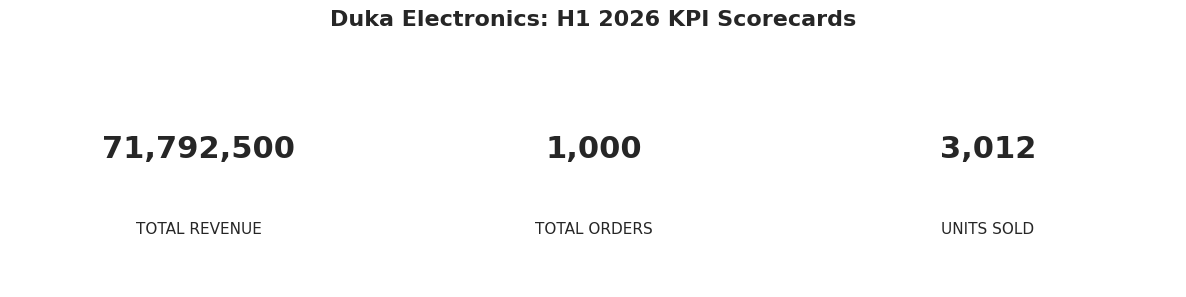

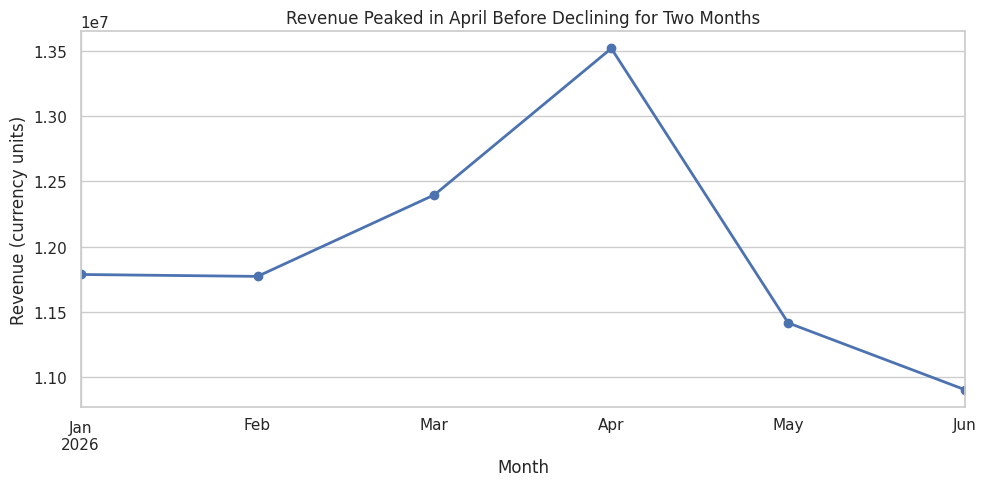

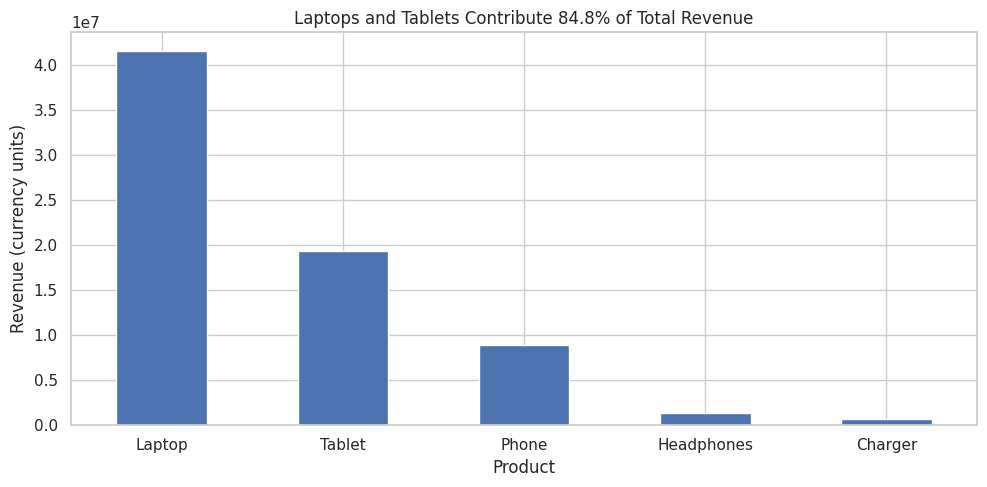

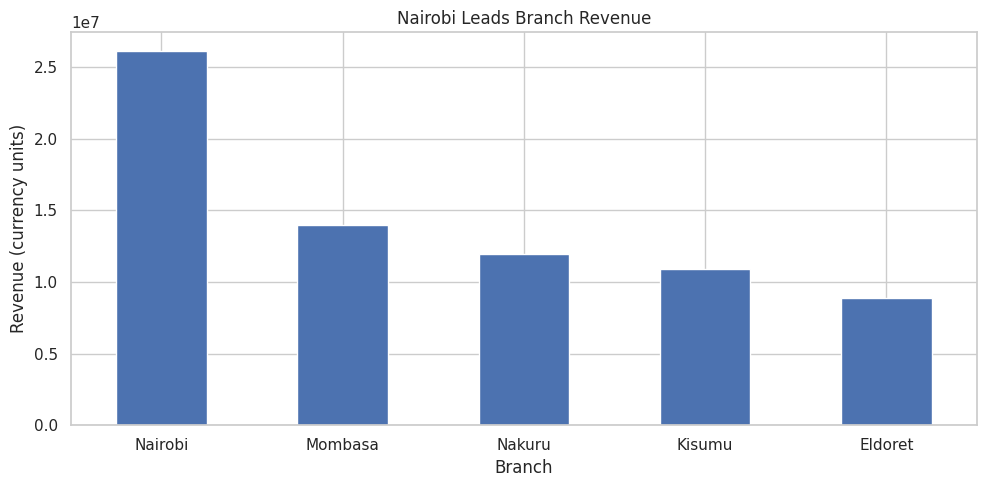

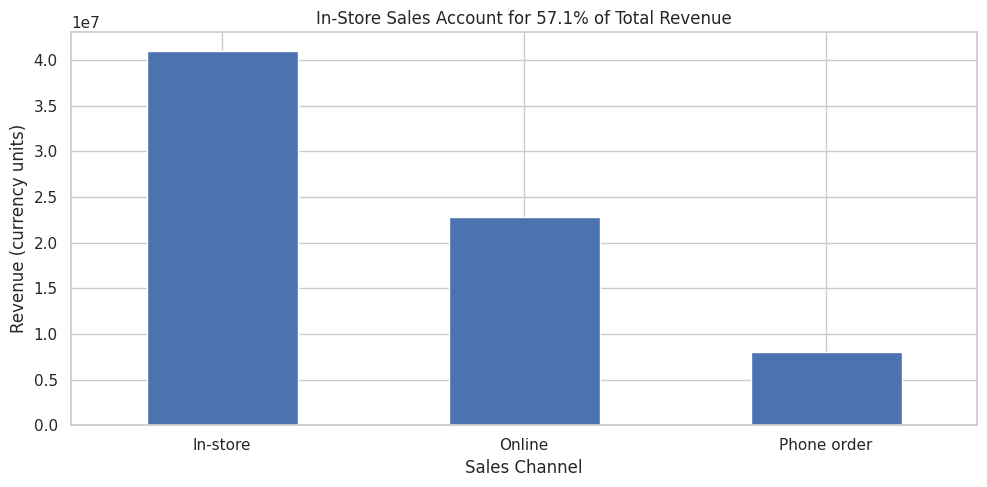

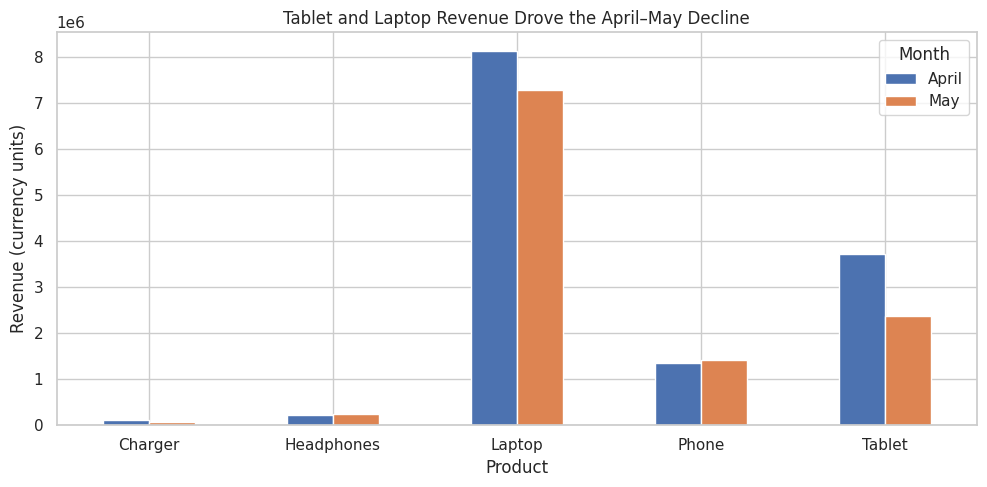

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10,5)
plt.rcParams["font.size"] = 11


fig,axes = plt.subplots(1,3,figsize=(12,3))
kpis=[
    ("TOTAL REVENUE", f"{total_revenue:,.0f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("UNITS SOLD", f"{total_units:,}")
]

for ax, (label,value) in zip(axes,kpis):
  ax.text(
      0.5,0.6,value,
      ha="center", va="center",
      fontsize=22,fontweight="bold"
  )
  ax.text(
      0.5,0.25,label,
      ha="center",va="center",
      fontsize=11
  )
  ax.set_axis_off()

fig.suptitle(
    "Duka Electronics: H1 2026 KPI Scorecards",
    fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.show()



monthly_revenue.plot(
    kind="line",
    marker="o",
    linewidth=2,
    figsize=(10, 5),
    title="Revenue Peaked in April Before Declining for Two Months"
)

plt.xlabel("Month")
plt.ylabel("Revenue (currency units)")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




product_revenue.plot(
    kind="bar",
    figsize=(10, 5),
    title="Laptops and Tablets Contribute 84.8% of Total Revenue"
)

plt.xlabel("Product")
plt.ylabel("Revenue (currency units)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "product_revenue.png",
    dpi=300,
    bbox_inches="tight"
)



plt.show()




branch_revenue.plot(
    kind="bar",
    figsize=(10, 5),
    title="Nairobi Leads Branch Revenue"
)

plt.xlabel("Branch")
plt.ylabel("Revenue (currency units)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "branch_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



channel_revenue.plot(
    kind="bar",
    figsize=(10, 5),
    title="In-Store Sales Account for 57.1% of Total Revenue"
)

plt.xlabel("Sales Channel")
plt.ylabel("Revenue (currency units)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "channel_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


april_may = monthly_product_revenue[["April", "May"]]

april_may.plot(
    kind="bar",
    figsize=(10, 5),
    title="Tablet and Laptop Revenue Drove the April–May Decline"
)

plt.xlabel("Product")
plt.ylabel("Revenue (currency units)")
plt.xticks(rotation=0)
plt.legend(title="Month")
plt.tight_layout()

plt.savefig(
    "april_may_product_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

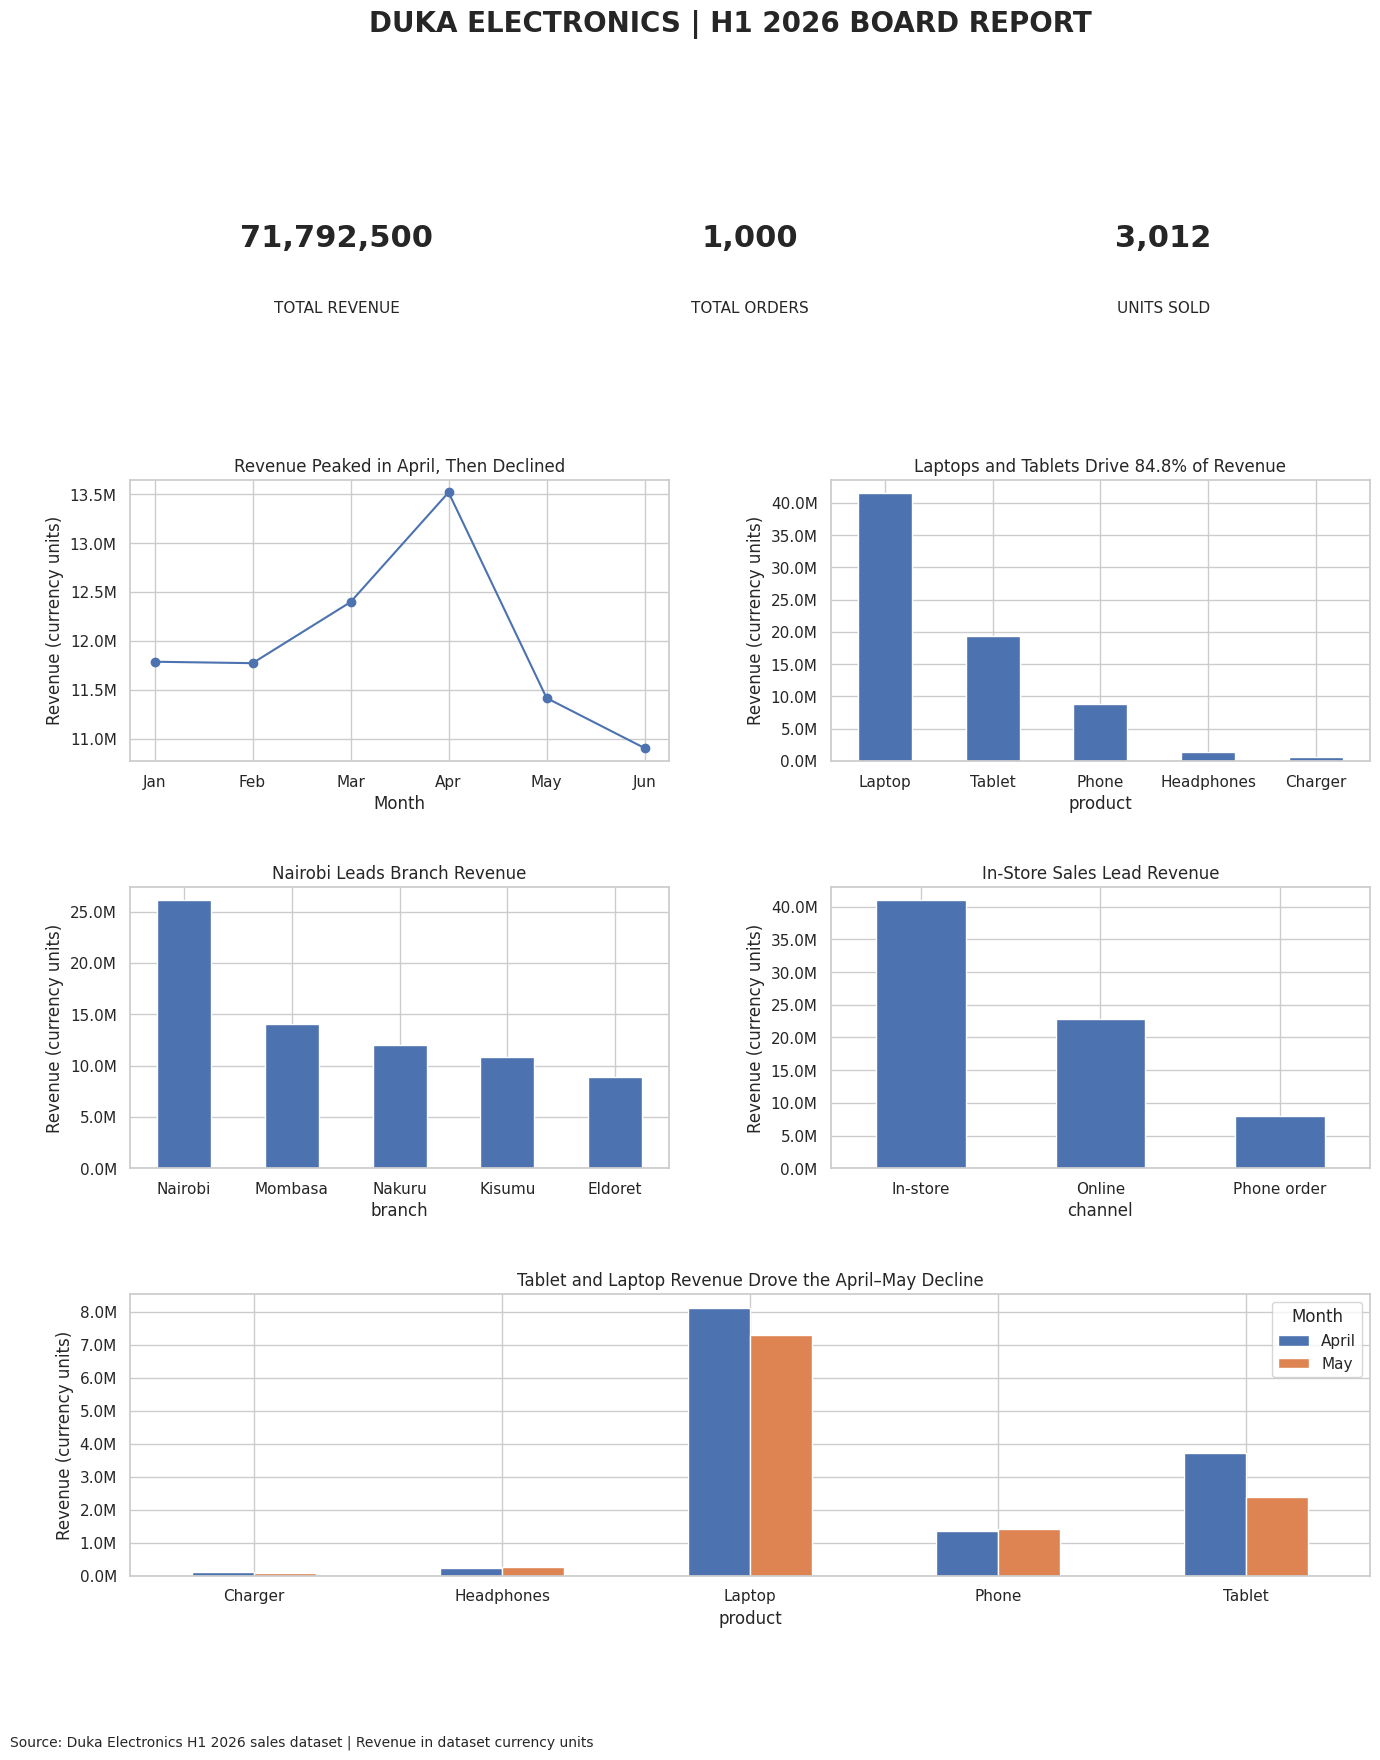

In [55]:

import os
os.makedirs("reports", exist_ok=True)

from matplotlib.ticker import FuncFormatter

million_formatter = FuncFormatter(
    lambda x, pos: f"{x / 1_000_000:.1f}M"
)




fig = plt.figure(figsize=(16, 18))

gs = fig.add_gridspec(
    4, 2,
    height_ratios=[0.7, 1.2, 1.2, 1.2],
    hspace=0.5,
    wspace=0.3
)

# Main title
fig.suptitle(
    "DUKA ELECTRONICS | H1 2026 BOARD REPORT",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

# KPI scorecards
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.axis("off")

kpis = [
    ("TOTAL REVENUE", f"{total_revenue:,.0f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("UNITS SOLD", f"{total_units:,}")
]

for i, (label, value) in enumerate(kpis):
    x = (i + 0.5) / 3

    ax_kpi.text(
        x, 0.65, value,
        ha="center",
        fontsize=22,
        fontweight="bold",
        transform=ax_kpi.transAxes
    )

    ax_kpi.text(
        x, 0.25, label,
        ha="center",
        fontsize=11,
        transform=ax_kpi.transAxes
    )

# Monthly revenue
ax1 = fig.add_subplot(gs[1, 0])
monthly_revenue.rename(
    index=lambda month: month.strftime("%b")
).plot(
    kind="line", marker="o", ax=ax1,
    title="Revenue Peaked in April, Then Declined"
)
ax1.set_ylabel("Revenue (currency units)")
ax1.set_xlabel("Month")

# Product revenue
ax2 = fig.add_subplot(gs[1, 1])
product_revenue.plot(
    kind="bar", ax=ax2,
    title="Laptops and Tablets Drive 84.8% of Revenue"
)
ax2.set_ylabel("Revenue (currency units)")
ax2.tick_params(axis="x", rotation=0)

# Branch revenue
ax3 = fig.add_subplot(gs[2, 0])
branch_revenue.plot(
    kind="bar", ax=ax3,
    title="Nairobi Leads Branch Revenue"
)
ax3.set_ylabel("Revenue (currency units)")
ax3.tick_params(axis="x", rotation=0)

# Channel revenue
ax4 = fig.add_subplot(gs[2, 1])
channel_revenue.plot(
    kind="bar", ax=ax4,
    title="In-Store Sales Lead Revenue"
)
ax4.set_ylabel("Revenue (currency units)")
ax4.tick_params(axis="x", rotation=0)

# April vs May
ax5 = fig.add_subplot(gs[3, :])
monthly_product_revenue[["April", "May"]].plot(
    kind="bar", ax=ax5,

    title="Tablet and Laptop Revenue Drove the April–May Decline"
)
ax5.set_ylabel("Revenue (currency units)")
ax5.tick_params(axis="x", rotation=0)
ax5.legend(title="Month"),

# Source line
fig.text(
    0.05, 0.015,
    "Source: Duka Electronics H1 2026 sales dataset | Revenue in dataset currency units",
    fontsize=10
)
for ax in [ax1, ax2, ax3, ax4, ax5]:
    ax.yaxis.set_major_formatter(million_formatter)

plt.savefig(
    "reports/duka_board_report.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

***# Before-and-After Design Comparison

The initial visualizations communicated the sales data but needed improvements to make the report easier for nontechnical board members to understand.

| Design element | Before | After | Reason for change |
|---|---|---|---|
| Number formatting | Scientific notation (e.g. 1e7) | Values displayed in millions | Makes revenue figures easier to interpret |
| Monthly labels | Longer date labels | Short month names (Jan–Jun) | Improves readability and saves space |
| Chart titles | Basic descriptive titles | Insight-driven titles | Communicates the main finding immediately |
| Legend | Technical label (order_date) | Clear label (Month) | Makes the comparison easier to understand |
| Layout | Individual charts | Combined single-page report | Gives the board one consolidated view |
| Source | Not consistently emphasized | Source line at the bottom | Improves transparency and context |

## Overall improvement

The final report uses clearer labels, consistent formatting, insight-driven titles and a consolidated layout. These changes make the report more accessible to nontechnical readers and easier to review on smaller screens.***

In [57]:
# Export the dataset with calculated revenue
sales.to_csv(
    "duka_sales_for_dashboard.csv",
    index=False
)

# Download the CSV to your computer
from google.colab import files

files.download("duka_sales_for_dashboard.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>